In [1]:
import pandas as pd
print("Pandas is working!")

Pandas is working!


In [2]:

import pandas as pd

# Load the customer reviews dataset
df = pd.read_csv("reviews_dataset (1).csv")

# Filter for healthcare reviews only
healthcare_df = df[df["category"] == "Healthcare"].copy()

# Check the number of rows and columns
print("Healthcare dataset shape:", healthcare_df.shape)

# Display the first five rows
healthcare_df.head()


Healthcare dataset shape: (2894, 23)


,review_id,user_id,username,review_title,review,sentiment,category,product,rating,verified_purchase,...,review_date,country,language,source,device,review_type,writing_style,emotion,recommendation_score,company_response
23,REV000024,USR450686,james_khan406,Nothing Special,"Based on my experiance, I purchased this Medic...",Neutral,Healthcare,Medicine,4,Yes,...,2024-08-15,UK,English,Google Reviews,Tablet,Long,formal,Neutral,7,We value your comments.
24,REV000025,USR370934,fatima_malik785,Decent Product,This was my first time using this Medical Serv...,Neutral,Healthcare,Medical Service,3,No,...,2025-10-11,USA,English,Google Reviews,Mobile,Medium,casual,Neutral,7,We value your comments.
35,REV000036,USR556912,charles_thomas528,It's Okay,I've been using this Hospital Visit every day....,Neutral,Healthcare,Hospital Visit,4,No,...,2026-07-05,Brazil,English,Google Reviews,Tablet,Medium,casual,Neutral,7,We value your comments.
50,REV000051,USR968941,jennifer_smith160,Very Impressed,The medical staff provided excellent care. Exc...,Positive,Healthcare,Dental Service,5,No,...,2025-11-13,Australia,English,Google Reviews,Tablet,Short,enthusiastic,Joy,10,We appreciate your positive review.
58,REV000059,USR283004,michael_johnson621,Fantastic Purchase,I purchased this Dental Service during a sale....,Positive,Healthcare,Dental Service,5,No,...,2026-05-15,Australia,English,Google Reviews,Tablet,Medium,casual,Joy,9,We're delighted that you enjoyed our product.


## 2. Dataset Overview
This step is for understanding the structure of the dataset. This includes examining the number of observations, available variables, data types and missing values.This step will help determine whether the dataset requires cleaning and which variables are suitable for sentiment analysis and topic modelling.

In [3]:

# Display the number of rows and columns
print("Dataset shape:", healthcare_df.shape)

# Display column names
print("\nColumn names:")
print(healthcare_df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
healthcare_df.info()

# Check missing values
print("\nMissing values:")
print(healthcare_df.isnull().sum())


Dataset shape: (2894, 23)

Column names:
['review_id', 'user_id', 'username', 'review_title', 'review', 'sentiment', 'category', 'product', 'rating', 'verified_purchase', 'helpful_votes', 'review_length', 'purchase_date', 'review_date', 'country', 'language', 'source', 'device', 'review_type', 'writing_style', 'emotion', 'recommendation_score', 'company_response']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 2894 entries, 23 to 45646
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   review_id             2894 non-null   object
 1   user_id               2894 non-null   object
 2   username              2894 non-null   object
 3   review_title          2894 non-null   object
 4   review                2894 non-null   object
 5   sentiment             2894 non-null   object
 6   category              2894 non-null   object
 7   product               2894 non-null   object
 8   ra

### Interpretation
The healthcare dataset contains 2894 reviews and 23 variables. These variables include customer review text, sentiment labels, ratings, healthcare service types and other review-related information.

The dataset contains 19 object-type variables and 4 integer variables. All 23 columns have 2894 non-null observations, indicating that there are no missing values.

# 3. Data cleaning and data quality 
This is to check if the dataset is suitable for analysis and model training. Checking for duplicates, empty reviews and inconcistent text formatting.

In [5]:

# Check for duplicate rows
print("Duplicate rows:", healthcare_df.duplicated().sum())

# Check for duplicate review IDs
print("Duplicate review IDs:",
      healthcare_df["review_id"].duplicated().sum())

# Check for duplicate review text
print("Duplicate review texts:",
      healthcare_df["review"].duplicated().sum())

# Check for empty reviews or reviews containing only spaces
empty_reviews = healthcare_df["review"].str.strip().eq("").sum()
print("Empty reviews:", empty_reviews)

# Check sentiment categories
print("\nSentiment categories:")
print(healthcare_df["sentiment"].value_counts())


Duplicate rows: 0
Duplicate review IDs: 0
Duplicate review texts: 0
Empty reviews: 0

Sentiment categories:
sentiment
Positive    1176
Negative     878
Neutral      840
Name: count, dtype: int64


### Interpretation
No missing values, duplicates or empty reviews were found. The dataset contains 1176 positive, 878 negative and 840 neutral reviews. No records need to be removed at this stage.

## Dataset Selection and Justification
The Customer Review Sentiment Dataset  was selected because it contains labelled customer reviews suitable for sentiment classification and topic modelling.

The analysis focuses on 2894 healthcare reviews with 23 variables, including review text, sentiment labels and healthcare service categories.

The dataset contains no missing values, duplicate reviews or empty review texts, supporting its quality for analysis.

Limitation: The reviews are synthetic and cover general healthcare services rather than South African medical aid complaints. Therefore, the findings demonstrate the analytical approach but cannot be generalised to actual medical aid customers.

# 4. Exploratory Data Analysis (EDA)
EDA examines sentiment distribution, review lengths and healthcare service categories to identify patterns and prepare the data for modelling.

### Sentiment distribution 


Matplotlib is building the font cache; this may take a moment.
/tmp/ipykernel_189/2505348437.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


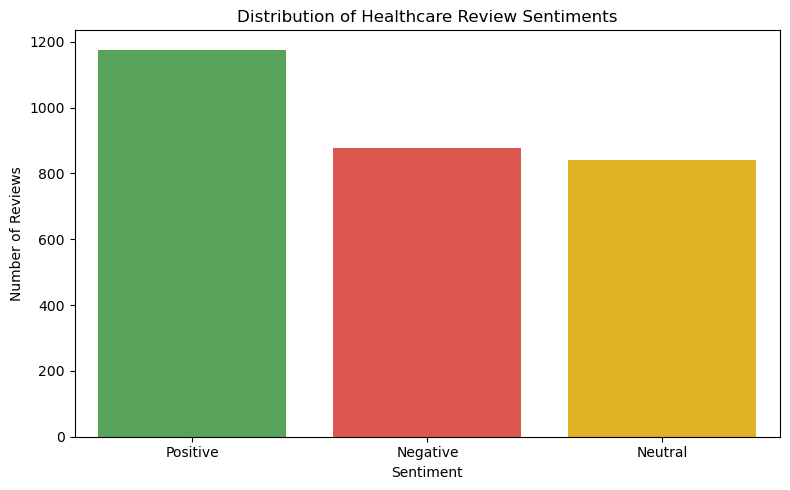

Sentiment percentages:
sentiment
Positive    40.64
Negative    30.34
Neutral     29.03
Name: proportion, dtype: float64


In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count reviews in each sentiment category
sentiment_counts = healthcare_df["sentiment"].value_counts()

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.countplot(
    data=healthcare_df,
    x="sentiment",
    order=["Positive", "Negative", "Neutral"],
    palette=["#4CAF50", "#F44336", "#FFC107"]
)

plt.title("Distribution of Healthcare Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

# Display sentiment percentages
sentiment_percentages = (
    healthcare_df["sentiment"].value_counts(normalize=True) * 100
)

print("Sentiment percentages:")
print(sentiment_percentages.round(2))


### Interpretation

Positive reviews account for 40.64% of the dataset, followed by negative reviews (30.34%) and neutral reviews (29.03%). Although positive sentiment is the most common, the proportion of negative reviews suggests areas of customer dissatisfaction worth investigating.

### Review Length Analysis
Review lengths are examined to understand how much text customers provide in their feedback.

count    2894.000000
mean       19.096752
std         7.351171
min         6.000000
25%        14.000000
50%        18.000000
75%        25.000000
max        43.000000
Name: word_count, dtype: float64


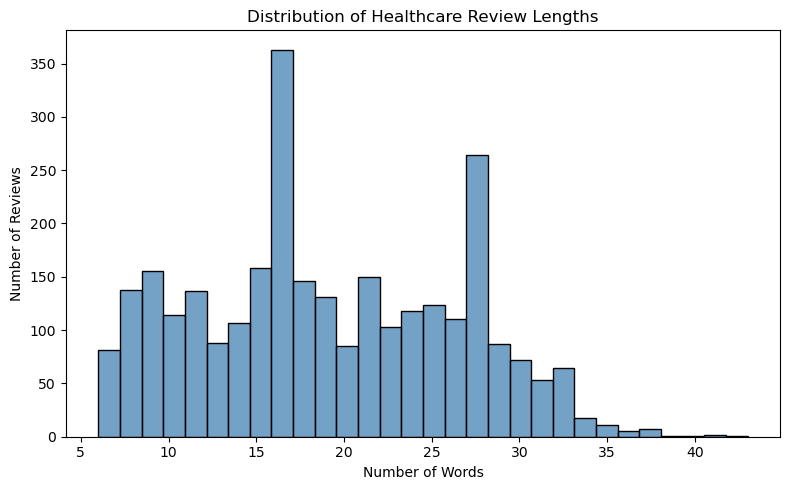

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
# Calculate review lengths using word counts
healthcare_df["word_count"] = (
    healthcare_df["review"].str.split().str.len()
)

# Display descriptive statistics
print(healthcare_df["word_count"].describe())

# Plot review length distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    healthcare_df["word_count"],
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Healthcare Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()


### Interpretation
Healthcare reviews contain an average of 19 words, with lengths ranging from 6 to 43 words. The median is 18 words, indicating that most reviews are relatively short.

### Healthcare Service Categories
This analysis examines the distribution of reviews across different healthcare service types.

Healthcare service categories:
product
Hospital Visit     606
Dental Service     595
Medicine           578
Health Checkup     561
Medical Service    554
Name: count, dtype: int64


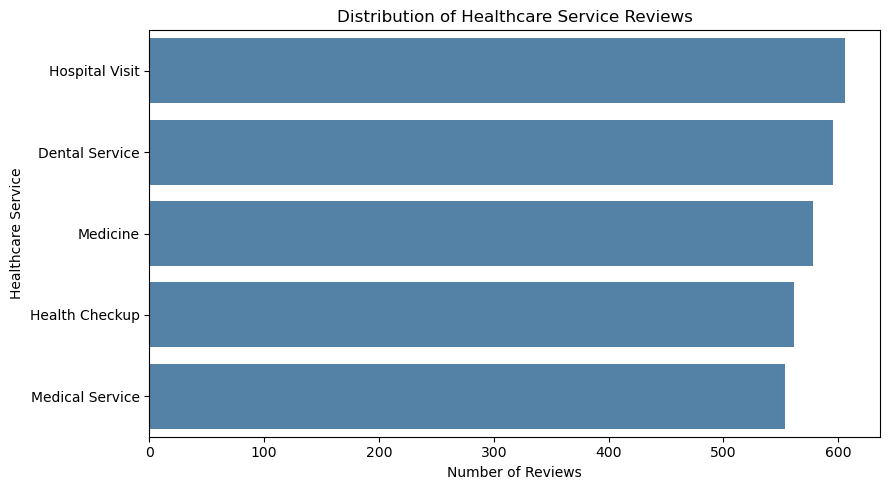

In [7]:

# Count reviews by healthcare service
service_counts = healthcare_df["product"].value_counts()

print("Healthcare service categories:")
print(service_counts)

# Visualise the distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    x=service_counts.values,
    y=service_counts.index,
    color="steelblue"
)

plt.title("Distribution of Healthcare Service Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Healthcare Service")

plt.tight_layout()
plt.show()


### Interpretation
Hospital visits have the highest number of reviews (606), followed by dental services (595). Medical services have the fewest (554). The relatively balanced distribution allows different healthcare services to be represented in the analysis.

# 5.Text  Preprocessing 
Review text will be converted to lowercase and cleaned by removing punctuation, numbers and unnecessary spaces. This helps standardise the text before modelling.

In [8]:

import re

# Function to clean review text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Apply text cleaning
healthcare_df["cleaned_review"] = healthcare_df["review"].apply(clean_text)

# Compare original and cleaned reviews
print(
    healthcare_df[["review", "cleaned_review"]]
    .head(5)
    .to_string(index=False)
)


                                                                                                                                                              review                                                                                                                                                cleaned_review
Based on my experiance, I purchased this Medicine during a sale. Overall, The healthcare service was average. Acceptable for the price. Overall, I'm very satisfied. based on my experiance i purchased this medicine during a sale overall the healthcare service was average acceptable for the price overall i m very satisfied
                                                       This was my first time using this Medical Service. The pricing met my expectations. Meets basic expectations.                                                    this was my first time using this medical service the pricing met my expectations meets basic expectations
                               

### Interpretation
The review text was successfully converted to lowercase, and punctuation, numbers and extra spaces were removed. The cleaned text is ready for feature extraction.

## 6. Feature Extraction
TF-IDF will be used to convert cleaned reviews into numerical features. It assigns greater importance to words that are more distinctive across reviews.

In [10]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialise TF-IDF vectoriser
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

print("TF-IDF vectoriser initialised successfully.")


TF-IDF vectoriser initialised successfully.


## 7.Training and Testing Data
The dataset will be divided into 80% training data and 20% testing data. Stratified sampling will preserve the proportion of each sentiment category in both sets.

In [11]:

from sklearn.model_selection import train_test_split

# Define features and target variable
X = healthcare_df["cleaned_review"]
y = healthcare_df["sentiment"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

# Check sentiment distribution
print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())


Training reviews: 2315
Testing reviews: 579

Training sentiment distribution:
sentiment
Positive    941
Negative    702
Neutral     672
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Positive    235
Negative    176
Neutral     168
Name: count, dtype: int64


### Interpretation
The dataset was split into 2315 training reviews (80%) and 579 testing reviews (20%). Stratified sampling maintained the sentiment distribution across both sets.

## 8.TF-IDF Transformation
TF-IDF is fitted on the training data and then applied to the testing data. This prevents information from the test set influencing feature extraction.

In [12]:

# Fit TF-IDF on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the fitted vectoriser
X_test_tfidf = tfidf.transform(X_test)

# Display feature matrix dimensions
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

# Display the number of extracted features
print("Number of features:", len(tfidf.get_feature_names_out()))


Training TF-IDF shape: (2315, 2188)
Testing TF-IDF shape: (579, 2188)
Number of features: 2188


### Interpretation
TF-IDF extracted 2,188 text features from the healthcare reviews. The training and testing matrices contain 2,315 and 579 reviews, respectively, with the same number of features.


## 9.Sentiment Classification
Logistic Regression was selected because it is suitable for text classification and works well with TF-IDF features. The model will be trained to predict three sentiment categories: Positive, Negative and Neutral.

In [13]:

from sklearn.linear_model import LogisticRegression

# Initialise Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict sentiment on the test set
y_pred = lr_model.predict(X_test_tfidf)

print("Logistic Regression model trained successfully.")

# Display sample predictions
print("\nFirst 10 predictions:")
print(y_pred[:10])


Logistic Regression model trained successfully.

First 10 predictions:
['Negative' 'Negative' 'Negative' 'Neutral' 'Negative' 'Positive'
 'Neutral' 'Neutral' 'Positive' 'Negative']


### Interpretation
The Logistic Regression model was successfully trained using TF-IDF features. It generated predictions for positive, negative and neutral reviews. Its performance will now be evaluated using the test dataset.


## Model Evaluation
The model's performance is evaluated using accuracy, precision, recall and F1-score. These metrics measure how effectively the model classifies customer sentiment.

In [14]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

# Display results
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       176
     Neutral       1.00      1.00      1.00       168
    Positive       1.00      1.00      1.00       235

    accuracy                           1.00       579
   macro avg       1.00      1.00      1.00       579
weighted avg       1.00      1.00      1.00       579



### Interpretation
The Logistic Regression model achieved 100% accuracy, precision, recall and F1-score, correctly classifying all 579 test reviews. Although these results indicate excellent performance, further investigation is needed to determine whether the synthetic dataset contains easily distinguishable sentiment patterns.


## 11.Confusion Matrix
A confusion matrix is used to examine the model's predictions across the three sentiment categories and identify any classification errors.

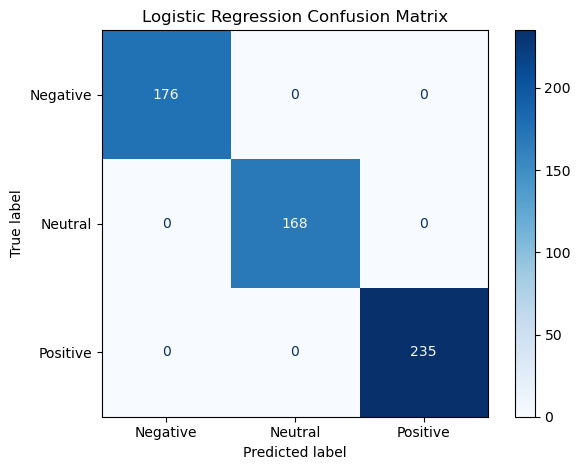

In [15]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define sentiment categories
labels = ["Negative", "Neutral", "Positive"]

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)

# Visualise confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()


### Interpretation
The confusion matrix shows that all 176 negative, 168 neutral and 235 positive reviews were correctly classified, with no errors. However, the perfect performance requires further investigation because the dataset contains synthetic reviews.

## 12.Investigating Model Performance
The model achieved perfect classification accuracy. The most influential TF-IDF features will be examined to determine whether the model relies on obvious sentiment-related words.

In [16]:

import pandas as pd

# Get TF-IDF feature names
feature_names = tfidf.get_feature_names_out()

# Display the most influential words for each sentiment
for i, sentiment in enumerate(lr_model.classes_):
    coefficients = lr_model.coef_[i]
    top_indices = coefficients.argsort()[-10:][::-1]

    top_features = pd.DataFrame({
        "Feature": feature_names[top_indices],
        "Coefficient": coefficients[top_indices].round(3)
    })

    print(f"\nTop 10 features for {sentiment}:")
    print(top_features.to_string(index=False))



Top 10 features for Negative:
             Feature  Coefficient
        disappointed        2.436
                star        1.928
       staff helpful        1.858
             helpful        1.858
communication better        1.746
               money        1.731
              clinic        1.682
overall disappointed        1.648
       communication        1.618
               worst        1.562

Top 10 features for Neutral:
               Feature  Coefficient
               average        3.491
            acceptable        2.656
                  okay        2.220
               special        2.082
    staff professional        1.972
              good bad        1.957
              ordinary        1.837
    average experience        1.824
                   bad        1.787
treatment satisfactory        1.772

Top 10 features for Positive:
              Feature  Coefficient
               highly        2.311
exceeded expectations        2.246
             exceeded        2.24

### Interpretation
The model relies on clear sentiment-related words, such as "disappointed" (negative), "average" (neutral) and "excellent" (positive). These patterns may explain its perfect accuracy on the synthetic dataset, although performance on real customer reviews remains uncertain.

## 13. Model Generalisation Test
The model will be tested on manually written healthcare reviews to assess its ability to classify sentiment beyond the original dataset.

In [17]:

# Create new healthcare reviews
new_reviews = [
    "The doctor was friendly, but I waited three hours for assistance.",
    "My medical claim was rejected without a clear explanation.",
    "The consultation was fine, nothing particularly good or bad.",
    "The hospital staff treated me with care and respect.",
    "The service was affordable, but the communication was poor."
]

# Clean the new reviews
cleaned_new_reviews = [clean_text(review) for review in new_reviews]

# Transform using the existing TF-IDF vectoriser
new_reviews_tfidf = tfidf.transform(cleaned_new_reviews)

# Predict sentiment
new_predictions = lr_model.predict(new_reviews_tfidf)

# Display results
results = pd.DataFrame({
    "Review": new_reviews,
    "Predicted Sentiment": new_predictions
})

print(results.to_string(index=False))


                                                           Review Predicted Sentiment
The doctor was friendly, but I waited three hours for assistance.            Positive
       My medical claim was rejected without a clear explanation.            Positive
     The consultation was fine, nothing particularly good or bad.             Neutral
             The hospital staff treated me with care and respect.            Positive
      The service was affordable, but the communication was poor.            Negative


### Interpretation
The model correctly classified some manually written reviews but struggled with negative and mixed feedback. This suggests that its perfect test accuracy may not reflect its performance on unfamiliar reviews.

## 14.Model Improvement
The Logistic Regression model will be retrained using adjusted TF-IDF and regularisation parameters. The aim is to improve its ability to classify unfamiliar reviews while maintaining good test performance.

In [18]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Initialise an improved TF-IDF vectoriser
tfidf_improved = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 3),
    min_df=2,
    sublinear_tf=True
)

# Transform training and testing data
X_train_improved = tfidf_improved.fit_transform(X_train)
X_test_improved = tfidf_improved.transform(X_test)

# Train an adjusted Logistic Regression model
lr_improved = LogisticRegression(
    C=0.5,
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

lr_improved.fit(X_train_improved, y_train)

# Predict test sentiment
y_pred_improved = lr_improved.predict(X_test_improved)

print("Improved model trained successfully.")
print("Number of features:", X_train_improved.shape[1])


Improved model trained successfully.
Number of features: 4150


### Model Comparison
The original and improved models are compared using accuracy, precision, recall and F1-score to determine whether the adjustments improved classification performance.


In [19]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Function to calculate evaluation metrics
def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted"),
        "Recall": recall_score(y_true, y_pred, average="weighted"),
        "F1-score": f1_score(y_true, y_pred, average="weighted")
    }

# Compare original and improved models
comparison = pd.DataFrame({
    "Original Model": evaluate_model(y_test, y_pred),
    "Improved Model": evaluate_model(y_test, y_pred_improved)
}).T

print(comparison.round(4))


                Accuracy  Precision  Recall  F1-score
Original Model    1.0000     1.0000  1.0000    1.0000
Improved Model    0.9983     0.9983  0.9983    0.9983


### Interpretation
The original model achieved 100% across all evaluation metrics, while the improved model achieved 99.83%. Although the adjusted model performed slightly worse on the test set, its ability to classify unfamiliar reviews still needs to be assessed.

## 15.Improved Model Generalisation Test
The improved model will be tested on the same manually written reviews to compare its predictions with those of the original model.

In [23]:

# Transform the same reviews using the improved TF-IDF vectoriser
new_reviews_improved = tfidf_improved.transform(cleaned_new_reviews)

# Generate predictions
improved_predictions = lr_improved.predict(new_reviews_improved)

# Compare predictions
generalisation_comparison = pd.DataFrame({
    "Review": new_reviews,
    "Original Model": new_predictions,
    "Improved Model": improved_predictions
})

print(generalisation_comparison.to_string(index=False))


                                                           Review Original Model Improved Model
The doctor was friendly, but I waited three hours for assistance.       Positive       Positive
       My medical claim was rejected without a clear explanation.       Positive       Positive
     The consultation was fine, nothing particularly good or bad.        Neutral        Neutral
             The hospital staff treated me with care and respect.       Positive       Positive
      The service was affordable, but the communication was poor.       Negative       Negative


### Interpretation
Both models produced identical predictions on the five unfamiliar reviews, including incorrectly classifying a rejected medical claim as positive. The adjustments did not demonstrate improved generalisation.

## 16.Final Model Selection
The original Logistic Regression model was retained because it achieved higher test accuracy (100%) than the adjusted model (99.83%). Both models struggled with unfamiliar negative feedback, highlighting limitations in generalising beyond the synthetic dataset.

## 17.Topic Modelling
Latent Dirichlet Allocation (LDA) will be used to identify recurring themes in healthcare reviews. Unlike sentiment classification, topic modelling groups frequently associated words to reveal common subjects discussed by customers.

In [24]:

from sklearn.feature_extraction.text import CountVectorizer

# Initialise CountVectorizer for topic modelling
count_vectorizer = CountVectorizer(
    max_features=3000,
    stop_words="english",
    min_df=5,
    max_df=0.90
)

# Convert cleaned reviews into word-count features
X_counts = count_vectorizer.fit_transform(
    healthcare_df["cleaned_review"]
)

# Display matrix dimensions
print("Document-term matrix shape:", X_counts.shape)
print("Number of features:", len(count_vectorizer.get_feature_names_out()))


Document-term matrix shape: (2894, 214)
Number of features: 214


### Interpretation
CountVectorizer generated a document-term matrix containing 2894 reviews and 214 word features. These features will be used to identify common themes through LDA topic modelling.

## 18.LDA Model Training
LDA will be trained using five initial topics to identify recurring themes in healthcare reviews. The topics will be examined to determine whether they represent meaningful areas of customer concern.

In [25]:

from sklearn.decomposition import LatentDirichletAllocation

# Initialise LDA model with five topics
lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    learning_method="batch",
    max_iter=20
)

# Train the LDA model
lda_model.fit(X_counts)

# Display the top 10 words for each topic
feature_names = count_vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_model.components_):
    top_words = topic.argsort()[-10:][::-1]
    words = [feature_names[i] for i in top_words]

    print(f"Topic {topic_idx + 1}: {', '.join(words)}")


Topic 1: process, appointment, hospital, service, clean, organized, efficient, smooth, clinic, waiting
Topic 2: visit, hospital, online, ordered, better, money, professional, doctor, staff, using
Topic 3: expectations, recommend, exceeded, highly, provider, decided, try, service, treatment, recommended
Topic 4: medical, service, excellent, wanted, share, staff, experience, ve, care, provided
Topic 5: overall, service, experience, average, visit, good, healthcare, price, purchased, reading


### Interpretation
The LDA model identified themes relating to appointments, hospital visits, customer expectations, medical care and overall satisfaction. However, some topics contain overlapping or generic terms, suggesting that further evaluation is needed.

## 19.LDA Model Evaluation
LDA models with different topic counts will be compared using perplexity to assess model fit and guide topic selection.

In [26]:

# Compare different numbers of topics
topic_counts = [3, 4, 5, 6, 7]

perplexity_results = []

for n in topic_counts:
    model = LatentDirichletAllocation(
        n_components=n,
        random_state=42,
        learning_method="batch",
        max_iter=20
    )

    model.fit(X_counts)

    perplexity_results.append({
        "Topics": n,
        "Perplexity": model.perplexity(X_counts)
    })

# Display comparison
perplexity_df = pd.DataFrame(perplexity_results)

print(perplexity_df.round(2))


   Topics  Perplexity
0       3      127.63
1       4      126.46
2       5      121.74
3       6      119.98
4       7      118.51


### Interpretation
Perplexity decreased from 127.63 with 3 topics to 118.51 with 7 topics. The 7-topic model achieved the lowest perplexity, suggesting a better statistical fit. However, topic interpretability must also be considered.

## 20.LDA Model Improvement
The LDA model will be retrained using seven topics, as this configuration achieved the lowest perplexity among those tested. The resulting topics will be examined for interpretability.

In [27]:

# Train LDA model with seven topics
lda_improved = LatentDirichletAllocation(
    n_components=7,
    random_state=42,
    learning_method="batch",
    max_iter=20
)

lda_improved.fit(X_counts)

# Display the top 10 words for each topic
feature_names = count_vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_improved.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")


Topic 1: hospital, clean, organized, expectations, clinic, waiting, basic, meets, buying, regret
Topic 2: visit, hospital, online, ordered, professional, doctor, purchase, felt, attentive, comfortable
Topic 3: money, staff, wasn, worth, explained, clearly, service, facility, waste, purchased
Topic 4: medical, service, excellent, purchase, staff, care, provided, using, don, think
Topic 5: service, average, overall, good, price, experience, visit, healthcare, acceptable, purchased
Topic 6: expectations, exceeded, treatment, try, decided, process, appointment, efficient, smooth, service
Topic 7: overall, experience, healthcare, highly, recommend, disappointed, recommended, service, provider, wanted


### Interpretation
The 7-topic model achieved lower perplexity and identified themes relating to hospital facilities, patient experiences, costs, medical care and appointment efficiency. Some topics still overlap, limiting their interpretability.

## 21.Common Customer Concerns
The 7-topic LDA model will be used to identify the dominant topic in each review. Topic frequencies among negative reviews will help highlight potential areas of customer dissatisfaction.

Dominant topics in negative reviews:
dominant_topic
1    158
2     88
3    245
4     96
5     35
6     61
7    195
Name: count, dtype: int64


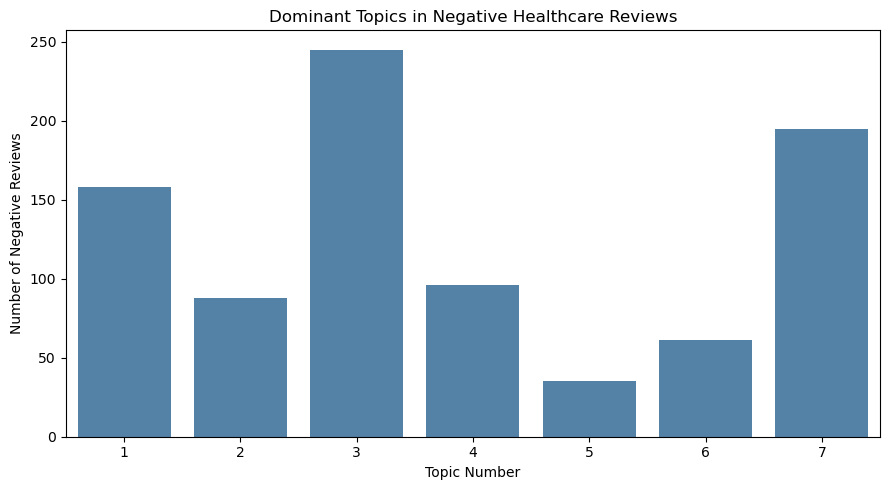

In [28]:

import numpy as np

# Calculate topic probabilities for each review
topic_probabilities = lda_improved.transform(X_counts)

# Assign each review its most likely topic
healthcare_df["dominant_topic"] = (
    np.argmax(topic_probabilities, axis=1) + 1
)

# Select negative reviews
negative_reviews = healthcare_df[
    healthcare_df["sentiment"] == "Negative"
]

# Count dominant topics in negative reviews
negative_topic_counts = (
    negative_reviews["dominant_topic"]
    .value_counts()
    .sort_index()
)

print("Dominant topics in negative reviews:")
print(negative_topic_counts)

# Visualise topic distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    x=negative_topic_counts.index,
    y=negative_topic_counts.values,
    color="steelblue"
)

plt.title("Dominant Topics in Negative Healthcare Reviews")
plt.xlabel("Topic Number")
plt.ylabel("Number of Negative Reviews")

plt.tight_layout()
plt.show()


### Interpretation
Topic 3 (costs and staff communication) has the most negative reviews (245), followed by Topic 7 (195) and Topic 1 (158). These results suggest that costs, communication and aspects of service experience warrant further investigation.

## 22.Review Examples by Topic
Sample negative reviews from the three most frequent topics will be examined to better understand customer concerns and validate the topic interpretations.

In [29]:

# Examine negative reviews from the three most frequent topics
for topic in [3, 7, 1]:
    print(f"\nTopic {topic} - Sample Negative Reviews:")

    examples = negative_reviews[
        negative_reviews["dominant_topic"] == topic
    ]["review"].head(5)

    for i, review in enumerate(examples, 1):
        print(f"{i}. {review}")



Topic 3 - Sample Negative Reviews:
1. I wouldn't choose this provider again. Very disappointed.
2. To be honest, I ordered this Health Checkup online. However, I wouldn't choose this provider again. Waste of money. I would buy it again.
3. Communication could have been much better. Save your money.
4. I wouldn't choose this provider again. I regret buying this. Still, it has a few good points.
5. The cleanliness was problematic. Waste of money. Still, it has a few good points. 😕

Topic 7 - Sample Negative Reviews:
1. I wanted to share my experience with this Health Checkup. Overall, I was disappointed with my experience. One star.
2. I recently bought this Medicine. Overall, I was disappointed with my experience. Not recommended. 💔
3. Honestly, I've been using this Health Checkup during my daily commute. However, I wouldn't choose this provider again. I would never buy this again. Overall, it met my expectations. 😕
4. I gotta say, I purchased this Hospital Visit during a sale. On top 

### Interpretation
Negative reviews in Topic 3 highlight costs and poor communication, while Topic 7 reflects general dissatisfaction. Topic 1 mainly concerns long waiting times. Some reviews contain contradictory statements, highlighting limitations in the synthetic dataset.

## Key Findings
The analysis identified three main areas of concern: costs and communication, overall dissatisfaction and waiting times. Negative reviews account for 30.34% of the dataset.
Although the sentiment classification model achieved 100% test accuracy, its performance on unfamiliar reviews was less reliable. These findings should therefore be interpreted cautiously because the dataset is synthetic and does not represent actual South African medical aid complaints.